# Notebook 2 - Semantic Classification via Zero-Shot NLP
## Forensic Network Analysis: The Epstein Corpus

**Pipeline:**
1. Risoluzione dell'ambiguità semantica degli archi relazionali.
2. Implementazione del modello NLI BART-large per classificazione Zero-Shot.
3. Stratificazione del network (Logistico, Sociale, Legale) per RQ1 e RQ3.


In [ ]:
import pandas as pd
import torch
import logging
from transformers import pipeline
from tqdm.auto import tqdm
import os

# --- 0. CONFIGURAZIONE LOGGING ---
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    datefmt='%Y-%m-%d %H:%M:%S'
)

# --- 1. CONFIGURAZIONE HARDWARE (Apple Silicon Optimization) ---
# Ottimizzazione specifica per architettura ARM (M2) tramite Metal Performance Shaders.
if torch.backends.mps.is_available():
    device = torch.device("mps")
    hf_device = "mps"
    logging.info("Hardware Setup: Apple Silicon (M2) rilevato. Accelerazione MPS abilitata.")
else:
    device = torch.device("cpu")
    hf_device = -1
    logging.warning("Hardware Setup: MPS non disponibile. Fallback su CPU.")

# --- 2. INIZIALIZZAZIONE PIPELINE NLP ---
logging.info("Inizializzazione del modello facebook/bart-large-mnli in corso...")
classifier = pipeline(
    "zero-shot-classification", 
    model="facebook/bart-large-mnli", 
    device=hf_device
)
logging.info("Modello caricato in memoria con successo.")

# --- 3. PREPARAZIONE DATI E DEFINIZIONE LABEL ---
candidate_labels = [
    "logistical coordination or travel planning", 
    "social networking, personal or political communication", 
    "legal procedural, investigative or oversight action"
]

input_path = '../data/edges_base.csv'
output_path = '../data/edges_classified.csv'

if not os.path.exists(input_path):
    logging.error(f"File di input non trovato: {input_path}")
    raise FileNotFoundError(f"File non trovato: {input_path}")

df_master = pd.read_csv(input_path)

# --- 4. MOTORE DI CLASSIFICAZIONE ZERO-SHOT (FULL RUN) ---
results = []
batch_size = 32  # Ottimizzato per i 16GB del tuo Mac M2
checkpoint_step = 5000

logging.info(f"Avvio classificazione totale su {len(df_master)} righe...")

for i in tqdm(range(0, len(df_master), batch_size), desc="Inferenza NLP"):
    batch = df_master.iloc[i : i + batch_size]
    
    # Costruzione del SUPER-PROMPT riga per riga con i Tags
    texts_to_classify = []
    for _, row in batch.iterrows():
        tags_raw = str(row.get('content_tags', ''))
        
        # Pulizia del JSON per rendere i tag leggibili dall'AI
        if tags_raw and tags_raw != 'nan':
            tags_clean = tags_raw.replace('[', '').replace(']', '').replace('"', '').replace(',', ', ')
        else:
            tags_clean = 'none'
        
        testo = f"The interaction is '{row['actor']} {row['action']} {row['target']}'. Document context: {row['one_sentence_summary']}. Document tags: {tags_clean}."
        texts_to_classify.append(testo)
    
    try:
        # Inferenza sul modello
        batch_predictions = classifier(texts_to_classify, candidate_labels, truncation=True)
        
        for pred in batch_predictions:
            results.append({
                'semantic_category': pred['labels'][0],
                'confidence': pred['scores'][0]
            })
    except Exception as e:
        logging.error(f"Fallimento al batch {i}. Dettagli: {str(e)}")
        # Placeholder in caso di errore per non sfalsare l'allineamento
        for _ in range(len(batch)):
            results.append({'semantic_category': 'ERROR', 'confidence': 0.0})
            
    # CHECKPOINTING: Salvataggio automatico ogni 5000 righe
    if (i + batch_size) % checkpoint_step < batch_size and i > 0:
        logging.info(f"Salvataggio intermedio: {len(results)} righe elaborate.")
        temp_df = pd.DataFrame(results)
        df_partial = pd.concat([df_master.iloc[:len(temp_df)].reset_index(drop=True), temp_df], axis=1)
        df_partial.to_csv(output_path, index=False)

# --- 5. CONSOLIDAMENTO E SALVATAGGIO FINALE ---
df_results = pd.DataFrame(results)
df_final = pd.concat([df_master.reset_index(drop=True), df_results], axis=1)

df_final.to_csv(output_path, index=False)
logging.info(f"Classificazione completata! File salvato in: {output_path}")

2026-03-13 15:35:17 - INFO - Hardware Setup: Apple Silicon (M2) rilevato. Accelerazione MPS abilitata.
2026-03-13 15:35:17 - INFO - Inizializzazione del modello facebook/bart-large-mnli in corso...
2026-03-13 15:35:17 - INFO - HTTP Request: HEAD https://huggingface.co/facebook/bart-large-mnli/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-03-13 15:35:17 - INFO - HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/bart-large-mnli/d7645e127eaf1aefc7862fd59a17a5aa8558b8ce/config.json "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

2026-03-13 15:35:17 - INFO - HTTP Request: GET https://huggingface.co/api/models/facebook/bart-large-mnli/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-03-13 15:35:18 - INFO - HTTP Request: GET https://huggingface.co/api/models/facebook/bart-large-mnli/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-03-13 15:35:20 - INFO - Modello caricato in memoria con successo.
2026-03-13 15:35:20 - INFO - Avvio classificazione totale su 107021 righe...


Inferenza NLP:   0%|          | 0/3345 [00:00<?, ?it/s]

2026-03-13 16:00:33 - INFO - Salvataggio intermedio: 5024 righe elaborate.
2026-03-13 16:27:57 - INFO - Salvataggio intermedio: 10016 righe elaborate.
2026-03-13 16:53:29 - INFO - Salvataggio intermedio: 15008 righe elaborate.
2026-03-13 17:16:59 - INFO - Salvataggio intermedio: 20000 righe elaborate.
2026-03-13 17:35:24 - INFO - Salvataggio intermedio: 25024 righe elaborate.
2026-03-13 17:55:26 - INFO - Salvataggio intermedio: 30016 righe elaborate.
2026-03-13 18:16:12 - INFO - Salvataggio intermedio: 35008 righe elaborate.
2026-03-13 18:36:43 - INFO - Salvataggio intermedio: 40000 righe elaborate.
2026-03-13 18:57:55 - INFO - Salvataggio intermedio: 45024 righe elaborate.
2026-03-13 19:19:14 - INFO - Salvataggio intermedio: 50016 righe elaborate.
2026-03-13 19:40:24 - INFO - Salvataggio intermedio: 55008 righe elaborate.
2026-03-13 20:01:37 - INFO - Salvataggio intermedio: 60000 righe elaborate.
2026-03-13 20:21:48 - INFO - Salvataggio intermedio: 65024 righe elaborate.
2026-03-13 20

--- MAPPING DELLE ETICHETTE ---
edge_label
Legal         49485
Social        48534
Logistical     9002
Name: count, dtype: int64

Archi con label 'Unknown' (errori o anomalie): 0


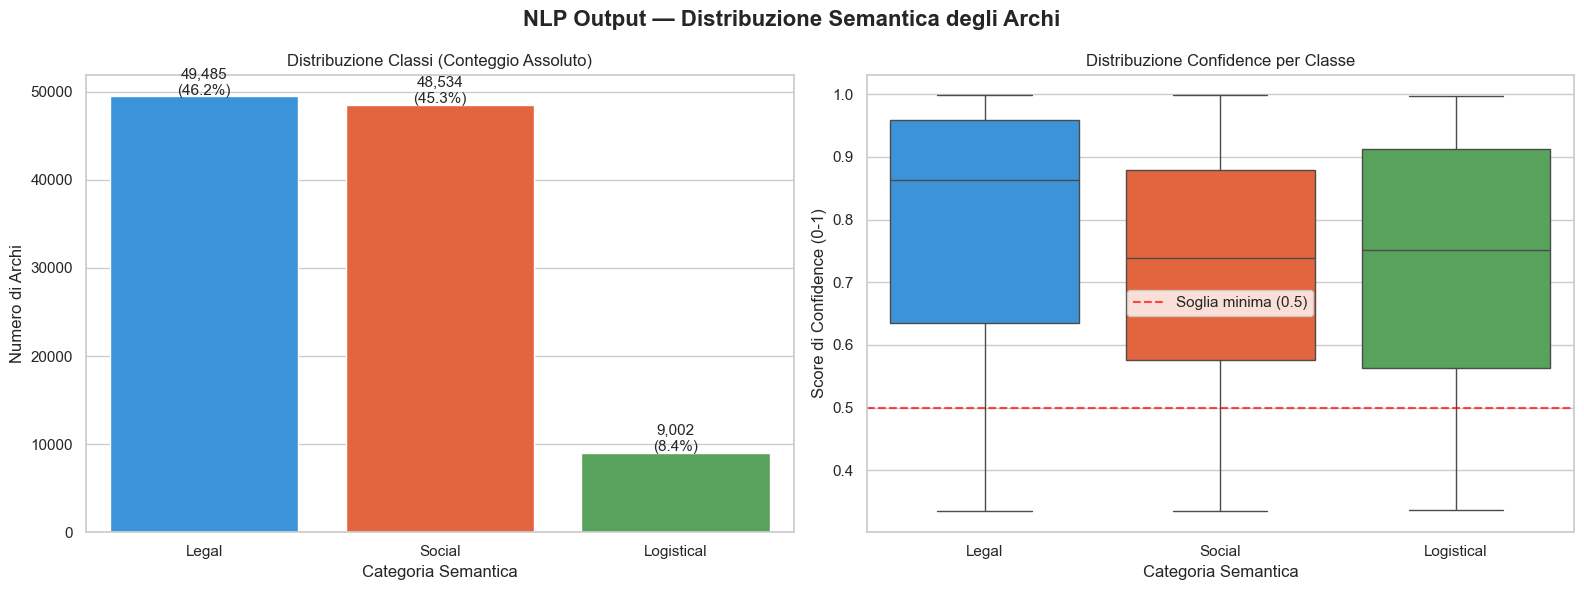


--- CONFIDENCE MEDIA PER CLASSE ---
              count   mean    std    min    25%    50%    75%    max
edge_label                                                          
Legal       49485.0  0.790  0.191  0.335  0.635  0.864  0.959  0.998
Logistical   9002.0  0.728  0.193  0.337  0.564  0.751  0.913  0.997
Social      48534.0  0.724  0.176  0.335  0.575  0.739  0.879  0.998

File aggiornato con colonna 'edge_label' salvato in: ../data/edges_classified.csv


In [ ]:
# Post-processing e analisi della distribuzione delle classi
# 1. Mapping delle label verbose del modello in categorie corte e pulite.
# 2. Analizzare la distribuzione delle 3 classi semantiche.
# 3. Valutare la confidence media per stimare l'affidabilità del modello.

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

output_path = '../data/edges_classified.csv'
df = pd.read_csv(output_path)

# STEP 1: LABEL MAPPING
# Il modello restituisce stringhe come etichette (es. "logistical  coordination or travel planning"). 
# Le mappiamo in label corte e standard che useremo come chiave di filtro.

label_map = {
    "logistical coordination or travel planning":       "Logistical",
    "social networking, personal or political communication": "Social",
    "legal procedural, investigative or oversight action":    "Legal"
}

# Applichiamo la mappa. Se per qualche ragione il modello restituisce 
# un'etichetta non prevista la marchiamo come 'Unknown'.
df['edge_label'] = df['semantic_category'].map(label_map).fillna('Unknown')

print("--- MAPPING DELLE ETICHETTE ---")
print(df['edge_label'].value_counts())
print(f"\nArchi con label 'Unknown' (errori o anomalie): {(df['edge_label'] == 'Unknown').sum()}")

# STEP 2: DISTRIBUZIONE DELLE CLASSI
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('NLP Output — Distribuzione Semantica degli Archi', fontsize=16, fontweight='bold')

# Grafico 1: conteggi assoluti
label_counts = df['edge_label'].value_counts()
sns.barplot(ax=axes[0], x=label_counts.index, y=label_counts.values,
            hue=label_counts.index, palette=['#2196F3', '#FF5722', '#4CAF50'], legend=False)
axes[0].set_title('Distribuzione Classi (Conteggio Assoluto)')
axes[0].set_ylabel('Numero di Archi')
axes[0].set_xlabel('Categoria Semantica')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 200, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)

# Grafico 2: distribuzione della confidence per classe
# Una confidence media bassa (< 0.5) su una classe segnala che il modello è incerto.
sns.boxplot(ax=axes[1], data=df[df['edge_label'] != 'Unknown'],
            x='edge_label', y='confidence',
            hue='edge_label', palette=['#2196F3', '#FF5722', '#4CAF50'], legend=False)
axes[1].set_title('Distribuzione Confidence per Classe')
axes[1].set_ylabel('Score di Confidence (0-1)')
axes[1].set_xlabel('Categoria Semantica')
axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='Soglia minima (0.5)')
axes[1].legend()

plt.tight_layout()
plt.show()

# STEP 3: STATISTICHE DI CONFIDENZA
print("\n--- CONFIDENCE MEDIA PER CLASSE ---")
print(df.groupby('edge_label')['confidence'].describe().round(3))

# Salviamo il file arricchito con la nuova colonna 'edge_label'
df.to_csv(output_path, index=False)
print(f"\nFile aggiornato con colonna 'edge_label' salvato in: {output_path}")

In [3]:
for thresh in [0.60, 0.65, 0.70, 0.75]:
    n = (df['confidence'] >= thresh).sum()
    print(f"≥{thresh}: {n:,} archi ({n/len(df)*100:.1f}%)")

≥0.6: 79,599 archi (74.4%)
≥0.65: 73,133 archi (68.3%)
≥0.7: 66,467 archi (62.1%)
≥0.75: 59,543 archi (55.6%)


In [ ]:
# Validazione Qualitativa (Human-in-the-Loop Sanity Check)
# Obiettivo:Campionare casualmente N archi per classe e verificare manualmente che le
# predizioni abbiano senso.

df = pd.read_csv('../data/edges_classified.csv')

N_SAMPLES = 5  # Campioni per classe da ispezionare manualmente

print("=" * 80)
print("VALIDAZIONE QUALITATIVA — CAMPIONE CASUALE PER CLASSE")
print("Istruzioni: leggi ogni riga e valuta se la label assegnata ha senso.")
print("=" * 80)

for label in ['Legal', 'Logistical', 'Social']:
    subset = df[df['edge_label'] == label].sample(n=N_SAMPLES, random_state=42)
    print(f"\n{'='*80}")
    print(f"  CLASSE: {label.upper()}")
    print(f"{'='*80}")
    for _, row in subset.iterrows():
        print(f"\n  TRIPLE:     {row['actor']} | {row['action']} | {row['target']}")
        print(f"  SUMMARY:    {str(row['one_sentence_summary'])[:120]}...")
        print(f"  CONFIDENCE: {row['confidence']:.3f}")
        print(f"  LABEL:      {row['edge_label']} ✓?")
        print(f"  {'-'*60}")

# --- ANALISI DEI CASI INCERTI ---
# Archi con confidence bassa sono i più rischiosi per l'analisi.
# Li isolare ci permette di decidere se escluderli o trattarli separatamente.
CONFIDENCE_THRESHOLD = 0.5
uncertain = df[df['confidence'] < CONFIDENCE_THRESHOLD]
print(f"\n\n--- ARCHI INCERTI (confidence < {CONFIDENCE_THRESHOLD}) ---")
print(f"Totale: {len(uncertain)} ({len(uncertain)/len(df)*100:.2f}% del dataset)")
print(f"Distribuzione per classe:\n{uncertain['edge_label'].value_counts()}")

VALIDAZIONE QUALITATIVA — CAMPIONE CASUALE PER CLASSE
Istruzioni: leggi ogni riga e valuta se la label assegnata ha senso.

  CLASSE: LEGAL

  TRIPLE:     Ballentine | asked for clarification | motion
  SUMMARY:    During a July 17, 2008 Code Enforcement Board meeting, officials including Fried, Ballentine, Randolph, Duemler, and Gre...
  CONFIDENCE: 0.979
  LABEL:      Legal ✓?
  ------------------------------------------------------------

  TRIPLE:     Michael Morell | stated in NBC interview that Christopher Steele used intermediaries to pay sources for the dossier | Christopher Steele
  SUMMARY:    Michael Morell discusses how Christopher Steele used intermediaries to pay sources for the Steele dossier, while the doc...
  CONFIDENCE: 0.526
  LABEL:      Legal ✓?
  ------------------------------------------------------------

  TRIPLE:     unknown person A | states encryption of | information
  SUMMARY:    A theoretical note describing a quantum Morse machine that purportedly trans